In [1]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
tries = 10
runs = 10

for i in range(runs):
    qc = QuantumCircuit(1)
    qc.h(0) # Hadamard gate
    sv = Statevector(qc)
    bits = sv.sample_memory(tries)
    cont = 0
    for i in bits: 
        if i == "1":
            cont = cont + 1
    #print("1:", cont)
    #print("0:", (tries-cont))
    #print(bits)
    print(sv.probabilities())

[0.5 0.5]
[0.5 0.5]
[0.5 0.5]
[0.5 0.5]
[0.5 0.5]
[0.5 0.5]
[0.5 0.5]
[0.5 0.5]
[0.5 0.5]
[0.5 0.5]


In [2]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

#prompt gemini: folosind un circuit cu un qbit, vreau sa i fac measurementul si citorea de probabilitati

qc = QuantumCircuit(1, 1)
qc.h(0)
qc.measure(0, 0)
simulator = AerSimulator()

shots_number = 1024

job = simulator.run(qc, shots=shots_number)
rezultat = job.result()
counts = rezultat.get_counts(qc)
print(f"Frequency (from {shots_number} counts): ", counts)

total_shots = sum(counts.values())
probabilitati = {stare: voturi / total_shots for stare, voturi in counts.items()}
print("Probabilities:", probabilitati)


Frequency (from 1024 counts):  {'1': 516, '0': 508}
Probabilities: {'1': 0.50390625, '0': 0.49609375}


In [3]:
import math

rad = 135
theta = math.radians(rad)
runs = 50
shots_number = 1024
epsilon = 0.1


qc = QuantumCircuit(1, 1)
qc.ry(theta,0)
qc.measure(0, 0)
simulator = AerSimulator()

for i in range(runs):
    
    job = simulator.run(qc, shots=shots_number)
    rezultat = job.result()
    counts = rezultat.get_counts(qc)

    total_shots = sum(counts.values())
    probabilitati = {stare: voturi / total_shots for stare, voturi in counts.items()}
    diff = abs(probabilitati.get("1") - probabilitati.get("0"))
    if diff <= epsilon:
        print("Fair toss")
    else:
        bias = abs(50 - probabilitati.get("1")*100)
        #bias_tails = abs(50 - probabilitati.get("0")*100) am demonstrat ca este acelasi bias si pt tails si pt heads
        print("bias (in percentage) ",bias)
        print("heads probability ", probabilitati.get("1")*100)
        print("tails probability ", probabilitati.get("0")*100,"\n")

bias (in percentage)  34.86328125
heads probability  84.86328125
tails probability  15.13671875 

bias (in percentage)  34.765625
heads probability  84.765625
tails probability  15.234375 

bias (in percentage)  36.23046875
heads probability  86.23046875
tails probability  13.76953125 

bias (in percentage)  34.08203125
heads probability  84.08203125
tails probability  15.91796875 

bias (in percentage)  33.984375
heads probability  83.984375
tails probability  16.015625 

bias (in percentage)  35.7421875
heads probability  85.7421875
tails probability  14.2578125 

bias (in percentage)  33.69140625
heads probability  83.69140625
tails probability  16.30859375 

bias (in percentage)  34.375
heads probability  84.375
tails probability  15.625 

bias (in percentage)  35.7421875
heads probability  85.7421875
tails probability  14.2578125 

bias (in percentage)  35.05859375
heads probability  85.05859375
tails probability  14.94140625 

bias (in percentage)  35.7421875
heads probability  8

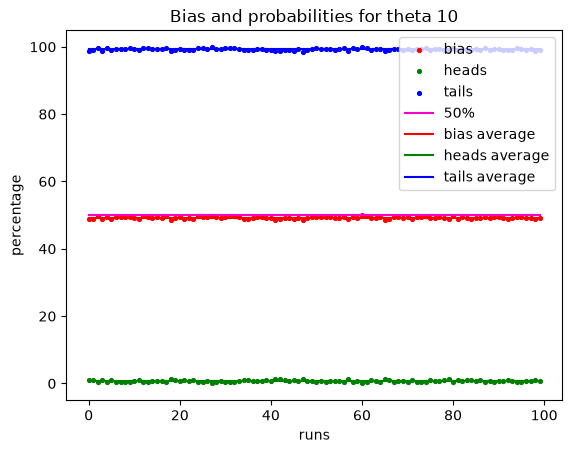

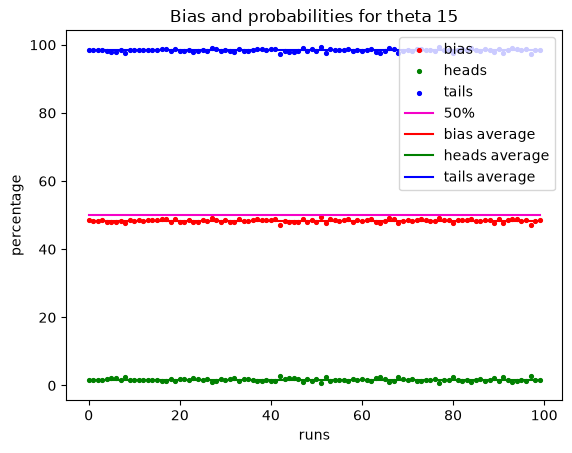

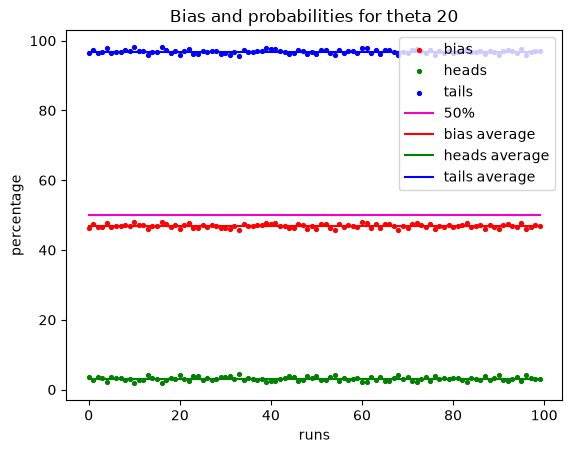

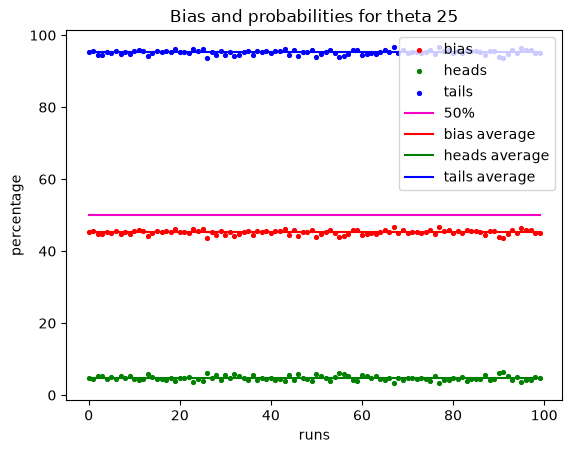

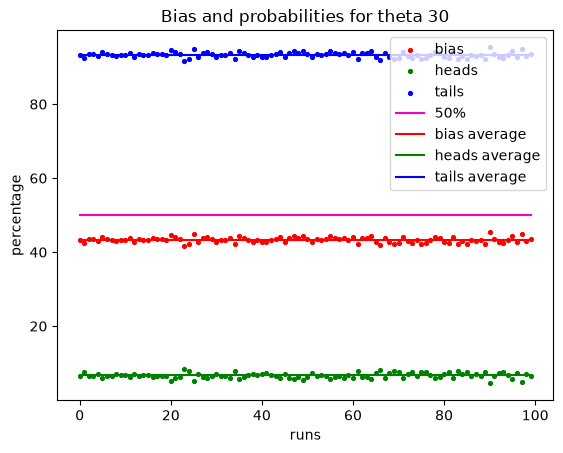

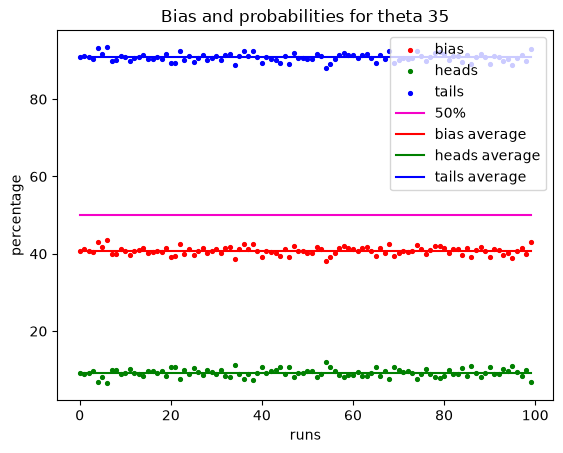

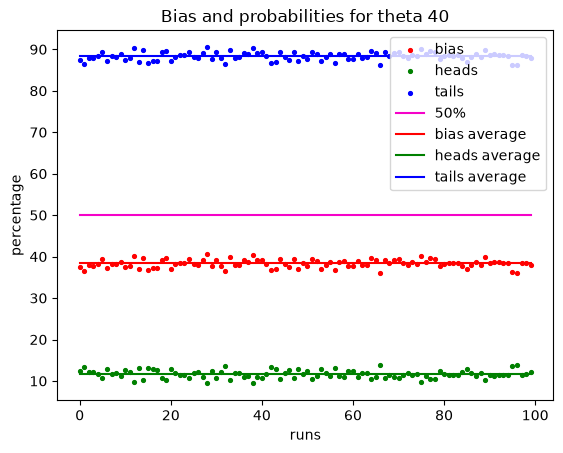

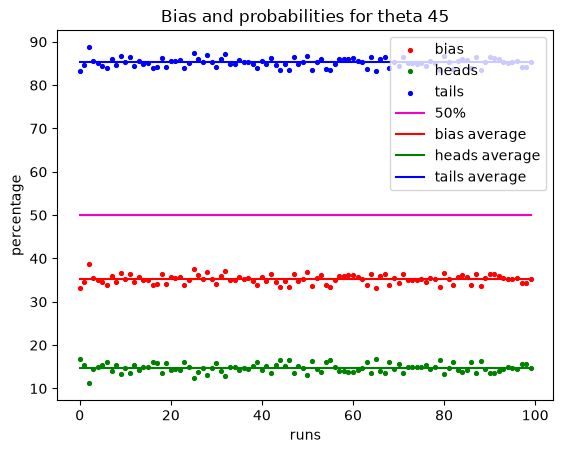

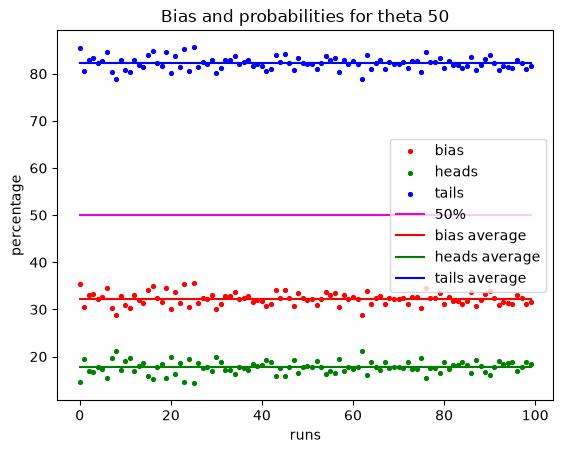

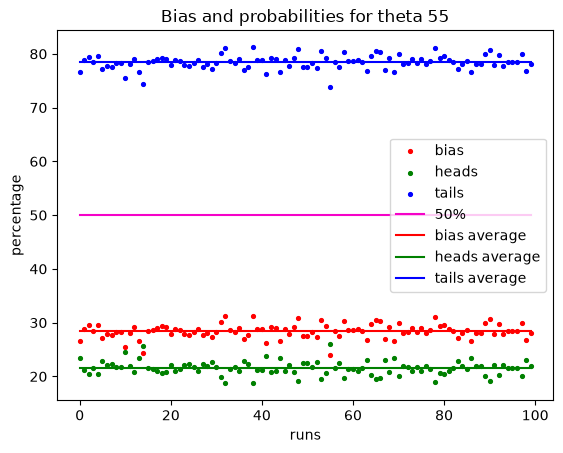

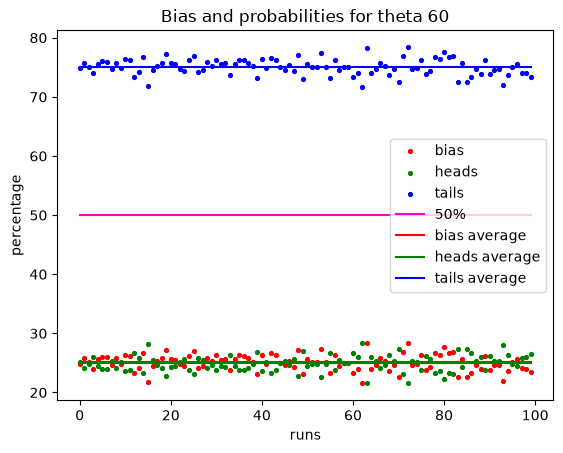

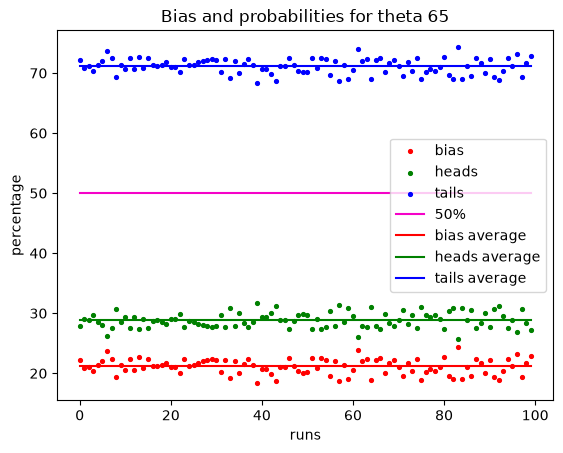

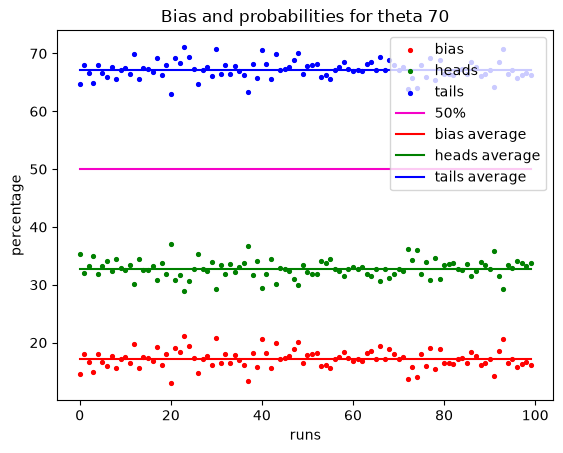

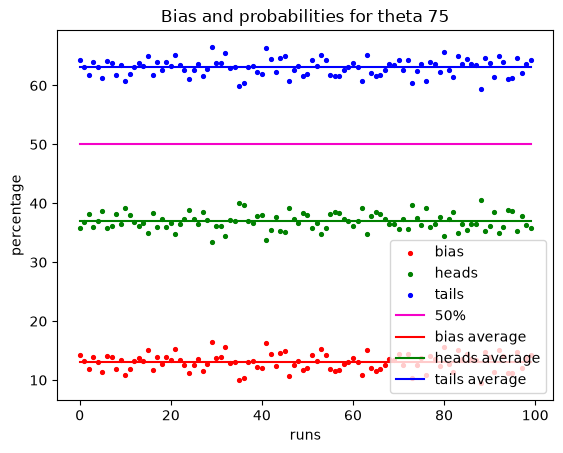

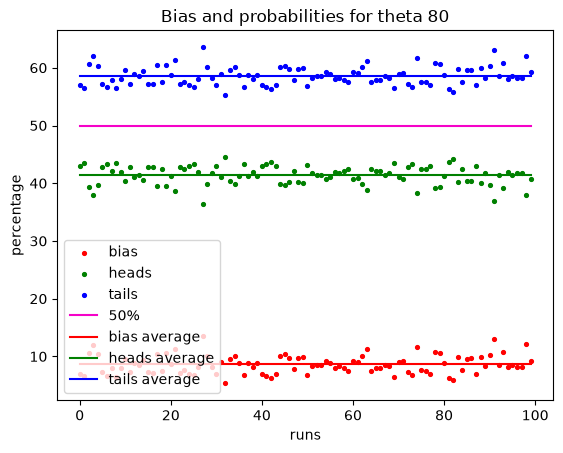

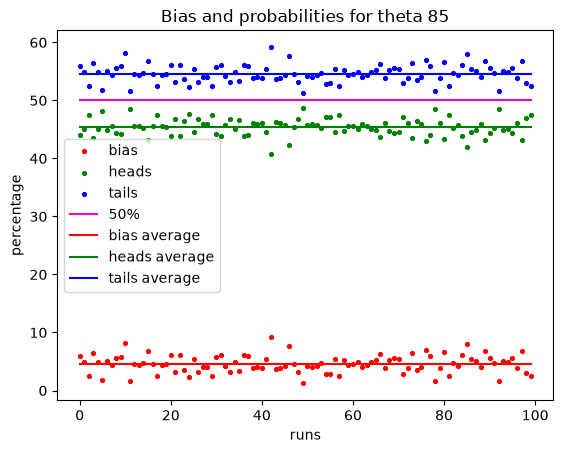

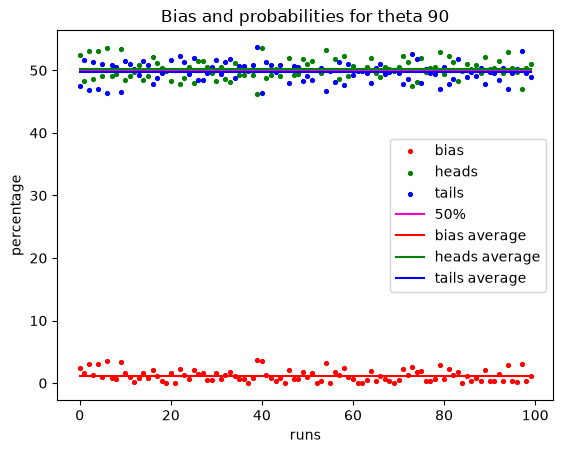

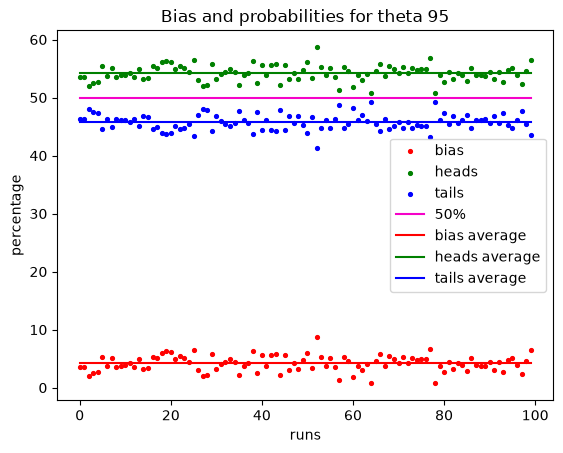

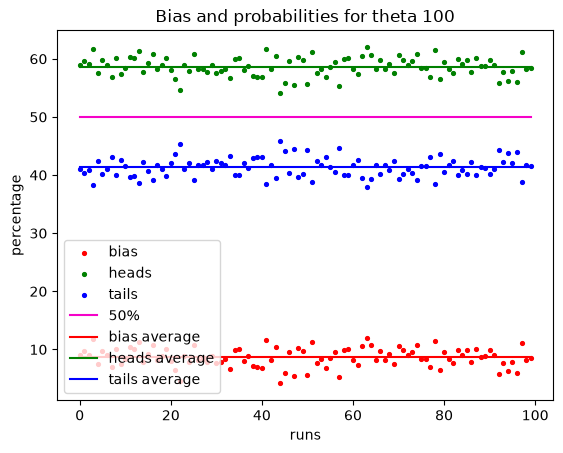

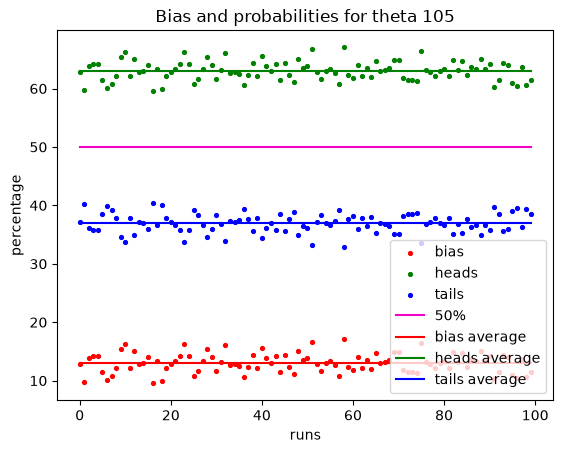

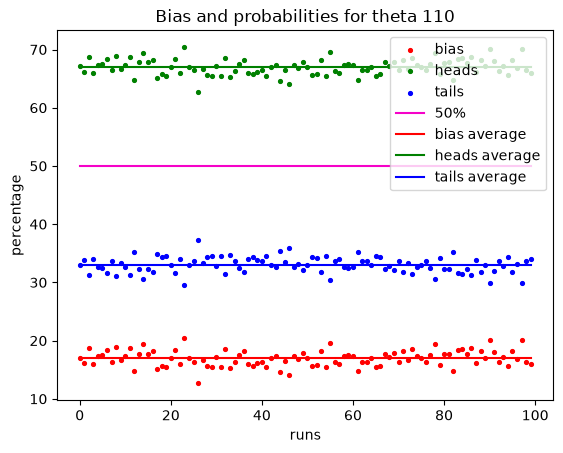

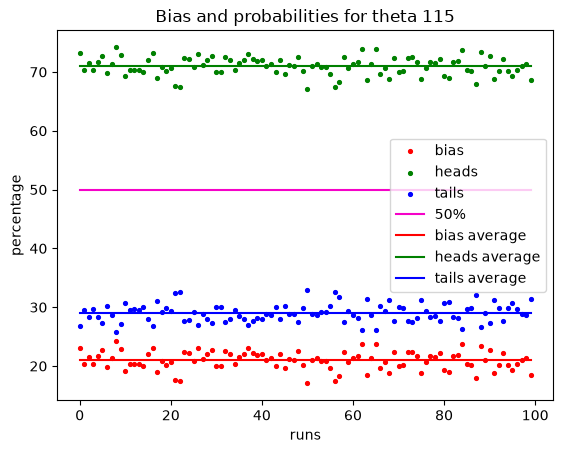

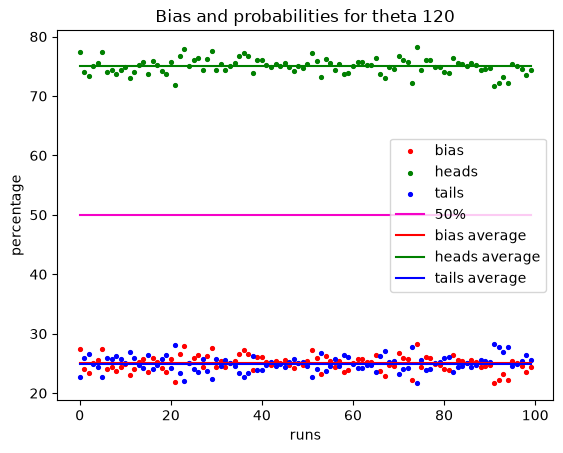

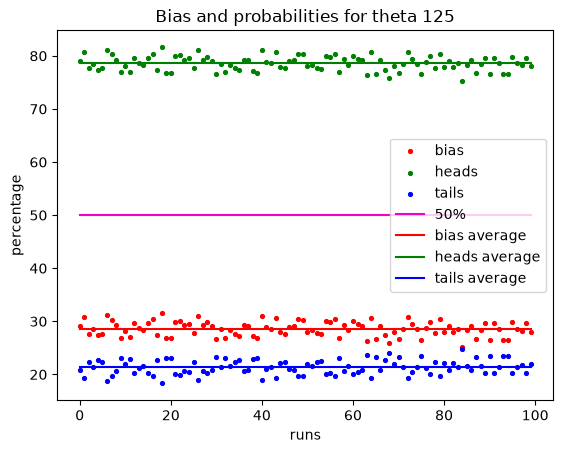

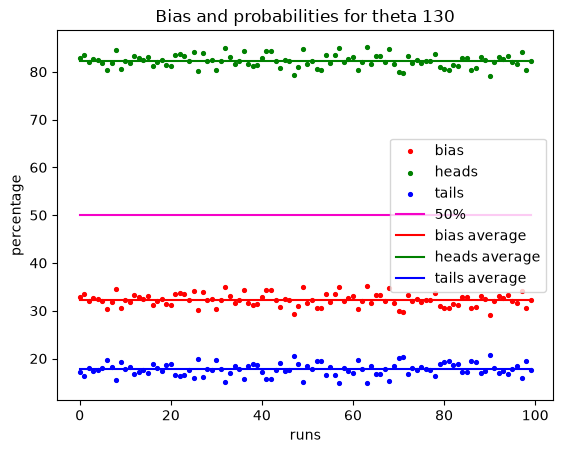

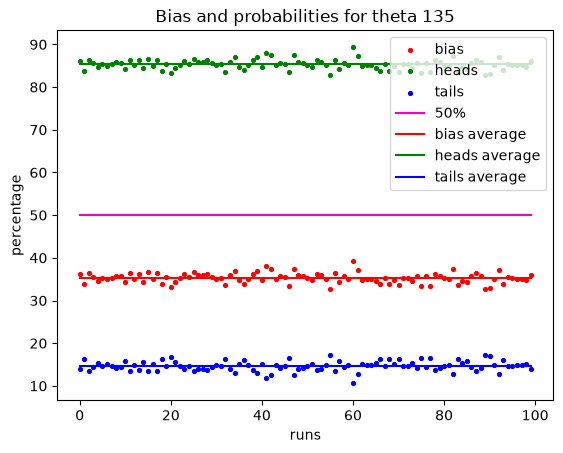

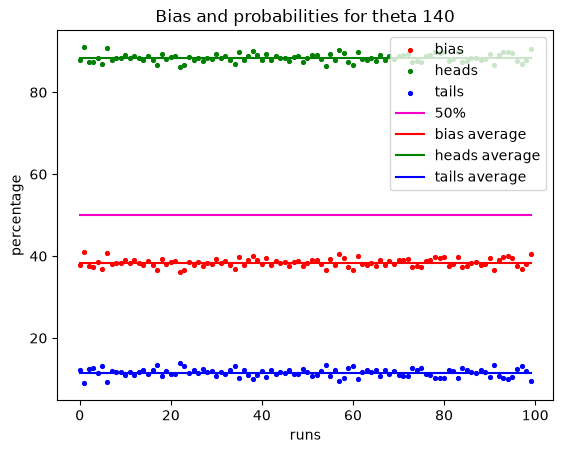

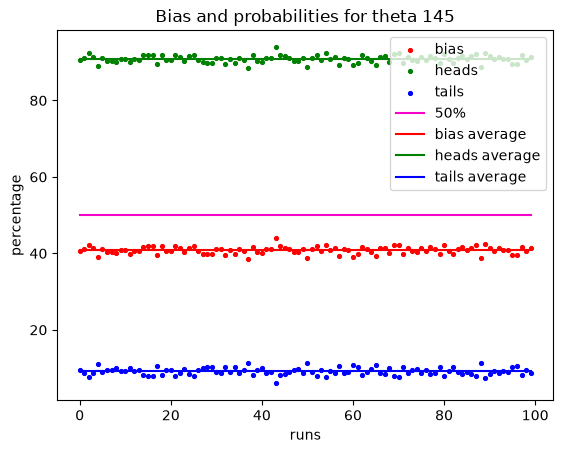

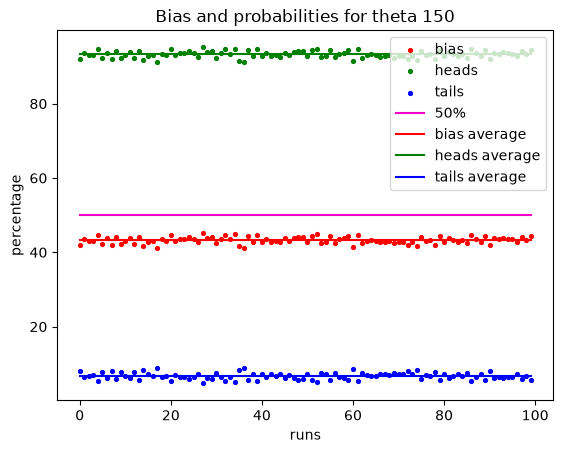

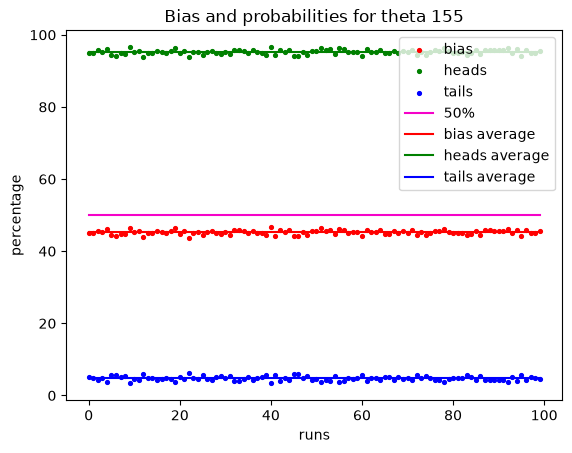

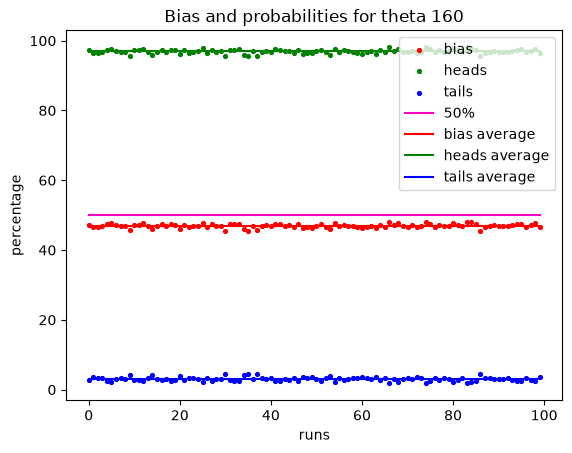

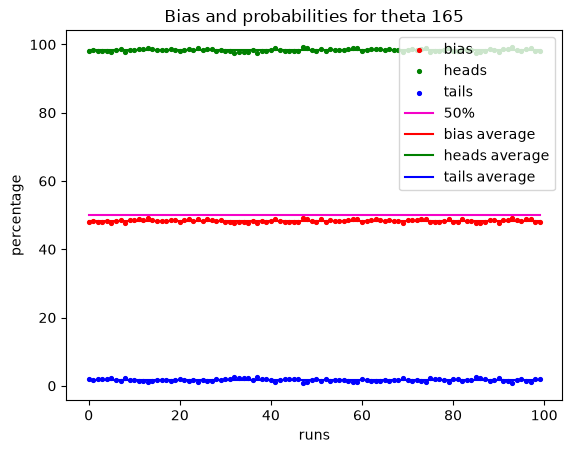

In [4]:
import math
import matplotlib.pyplot as plt

for rad in range(10, 170, 5):
# 8 < theta < 171
#rad = 90
    theta = math.radians(rad)
    runs = 100
    shots_number = 1024
    epsilon = 0.1
    
    
    qc = QuantumCircuit(1, 1)
    qc.ry(theta,0)
    qc.measure(0, 0)
    simulator = AerSimulator()
    
    x1=[0] * runs
    x2=[0] * runs
    x3=[0] * runs
    
    for i in range(runs):
        
        job = simulator.run(qc, shots=shots_number)
        rezultat = job.result()
        counts = rezultat.get_counts(qc)
    
        total_shots = sum(counts.values())
        probabilitati = {stare: voturi / total_shots for stare, voturi in counts.items()}
        diff = abs(probabilitati.get("1") - probabilitati.get("0"))
        bias = abs(50 - probabilitati.get("1")*100)
            #bias_tails = abs(50 - probabilitati.get("0")*100) am demonstrat ca este acelasi bias si pt tails si pt heads
        heads = probabilitati.get("1")*100
        tails = probabilitati.get("0")*100
        x1[i] = bias
        x2[i] = heads
        x3[i] = tails
    
    #height = [bias,probabilitati.get("1")*100,probabilitati.get("0")*100]
    #left = [0,50,100]
    #tick_label = ['bias', 'heads probability', 'tails probability']
    y = [i for i in range(runs)]
    plt.scatter(y, x1, label="bias", color="red", marker=".", s=30)
    plt.scatter(y, x2, label="heads", color="green", marker=".", s=30)
    plt.scatter(y, x3, label="tails", color="blue", marker=".", s=30)

    s1 = 0
    s2 = 0
    s3 = 0
    
    for j in range(runs):
        s1 = s1 + x1[j]
        s2 = s2 + x2[j]
        s3 = s3 + x3[j]
        
    med1 = s1/runs
    med2 = s2/runs
    med3 = s3/runs
    
    y_med = [50 for i in range(runs)]
    x_med = [i for i in range(runs)]
    
    plt.plot(x_med, y_med, label = '50%', color = '#f502c8')
    plt.plot(x_med, [med1 for i in range(runs)] , label = 'bias average', color = 'red')
    plt.plot(x_med, [med2 for i in range(runs)] , label = 'heads average', color = 'green')
    plt.plot(x_med, [med3 for i in range(runs)] , label = 'tails average', color = 'blue')
    
    # naming the x axis
    plt.xlabel('runs')
     # naming the y axis
    plt.ylabel('percentage')
        
        # giving a title to my graph
    plt.title(f"Bias and probabilities for theta {rad}")
    plt.legend()
        # function to show the plot
    plt.show()
        